<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-066a-allows-and-forbids.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 066a. What quantum information allows and forbids

A register of $N$ qubits is described by $2^N$ complex amplitudes, and it is tempting to regard it as a memory of $2^N$ numbers that we can copy, read out and process at will. Quantum mechanics limits this picture, and it also gives tools that no classical memory has. We study nine of these limits and tools with small computations on one, two and a few qubits. The notebook assumes the one-qubit gates, CNOT, density matrices, the partial trace and the Kraus form of noise channels.

The operations are the same as before. We prepare states with gates, let them evolve under gates or noise channels, and measure them, which returns bit strings with the probabilities of the Born rule. The quantities we compute are fidelities, success probabilities of a measurement, von Neumann entropies in bits, expectation values of Pauli strings, eigenvalues of matrices built from a state or a channel, and variances of a generator.

Section 1 shows that an unknown state cannot be copied. Section 2 finds the best measurement that tells two states apart from one copy, and Section 3 bounds the number of classical bits that $N$ qubits can carry. Section 4 states that CNOT and single-qubit rotations are universal and counts the parameters of an $N$-qubit unitary, and its optional Section 4.1 builds a controlled gate from two CNOT gates and rotations. Section 5 follows Pauli strings through circuits of Clifford gates with a classical bit update, and Section 6 shows that the expectation values of a uniformly random state concentrate at zero, and its optional Section 6.1 shows that random Clifford circuits reproduce the same second moments. Sections 0 to 6 without Sections 4.1 and 6.1 form the core route. Section 7 represents a noise channel by a two-qubit state, the Choi state, Section 8 uses the partial transpose to detect entanglement of mixed states, and Section 9 turns entanglement into precision of a phase estimate through the quantum Fisher information. Sections 7 to 9 can be finished at home.

Qubit 0 is the most significant bit, so the amplitude of the bit string $b_0b_1\dots b_{N-1}$ sits at index $\sum_q b_q2^{N-1-q}$. We use $|0\rangle=|{\uparrow}\rangle$, the rotations $\hat R_{\hat P}(\theta)=e^{-i\theta\hat P/2}$, and entropies in bits.

## 0. Tools

We use NumPy and SciPy in double precision and Matplotlib for the figures. Every claim below is checked with an `assert`. Figures are saved to files, and the numbers quoted elsewhere are collected in a dictionary and written as LaTeX macros at the end.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
OUT = Path("classroom_results"); OUT.mkdir(exist_ok=True)
NUMBERS = {}
started = time.perf_counter()
rng = np.random.default_rng(66)                 # fixed seed for every random draw of the notebook
TOL = 1e-10

# course palette (muted)
NAVY, BLUE, SKY, ORANGE, GREEN, GRAY = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#1B7F36", "#5A6270"

def make_figures(name, panels, notes_size=(6.6, 2.9), slide_size=(3.1, 2.05)):
    # notes: one figure with the panels side by side at 11 pt; slides: one figure per panel at 11 pt, 3.1 x 2.05 in.
    # Both are saved at their final printed size, so the fonts keep 11 pt when placed without scaling.
    rc = {"font.size": 11, "axes.labelsize": 11, "legend.fontsize": 11, "xtick.labelsize": 11,
          "ytick.labelsize": 11, "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False}
    with plt.rc_context(rc):
        fig, axes = plt.subplots(1, len(panels), figsize=notes_size, constrained_layout=True)
        axes = np.atleast_1d(axes)
        for k, (ax, panel) in enumerate(zip(axes, panels)):
            panel(ax)
            if len(panels) > 1:
                ax.text(-0.02, 1.02, f"({'abcd'[k]})", transform=ax.transAxes, va="bottom", ha="right")
        fig.savefig(FIG / f"fig_lab066a_{name}.pdf"); fig.savefig(FIG / f"fig_lab066a_{name}.png", dpi=150)
        plt.show()
        for k, panel in enumerate(panels):
            fs, ax = plt.subplots(figsize=slide_size, constrained_layout=True)
            panel(ax)
            fs.savefig(FIG / f"fig_lab066a_{name}_s{k + 1}.pdf"); fs.savefig(FIG / f"fig_lab066a_{name}_s{k + 1}.png", dpi=150)
            plt.close(fs)

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = (X + Z) / np.sqrt(2)
S = np.diag([1, 1j])
T = np.diag([1, np.exp(1j * np.pi / 4)])
ket0, ket1 = np.array([1, 0], dtype=complex), np.array([0, 1], dtype=complex)
plus, minus = (ket0 + ket1) / np.sqrt(2), (ket0 - ket1) / np.sqrt(2)
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], dtype=complex)
phi_plus = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}

def kron_all(*fs):
    out = np.array([[1.0 + 0j]]) if fs[0].ndim == 2 else np.array([1.0 + 0j])
    for f in fs:
        out = np.kron(out, f)
    return out

def pauli_string(s):
    # "XIZ" -> X (x) I (x) Z, qubit 0 leftmost
    return kron_all(*[PAULI[c] for c in s])

def dm(psi):
    return np.outer(psi, psi.conj())

def entropy_bits(rho):
    lam = np.linalg.eigvalsh(rho)
    lam = lam[lam > 1e-14]
    return float(-np.sum(lam * np.log2(lam)))

def haar_states(d, k):
    # k Haar-random pure states in dimension d: normalised complex Gaussian vectors
    v = rng.normal(size=(k, d)) + 1j * rng.normal(size=(k, d))
    return v / np.linalg.norm(v, axis=1, keepdims=True)

def haar_unitary(d):
    # QR decomposition of a complex Gaussian matrix, with the phases of R fixed
    A = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))
    Q, R = np.linalg.qr(A)
    return Q * (np.diag(R) / np.abs(np.diag(R)))

assert np.allclose(pauli_string("XZ"), np.kron(X, Z))
assert np.allclose(CNOT @ np.kron(H, I2) @ np.kron(ket0, ket0), phi_plus)
print("tools ready")

tools ready


## 1. No cloning

A classical bit can be copied, and a CNOT gate copies the bit of its control qubit into a target qubit prepared in $|0\rangle$, $\widehat{\mathrm{CNOT}}|b\rangle|0\rangle=|b\rangle|b\rangle$ for $b=0,1$. We ask whether some unitary $\hat U$ copies every state of a qubit,
$$\hat U\,|\psi\rangle|0\rangle=|\psi\rangle|\psi\rangle\qquad\text{for all }|\psi\rangle. \tag{1}$$
If it copies two states $|\psi\rangle$ and $|\varphi\rangle$, the inner product of the two inputs equals that of the two outputs, because a unitary preserves inner products,
$$\langle\varphi|\psi\rangle\,\langle0|0\rangle=\langle\varphi|\psi\rangle^2. \tag{2}$$
Taking the modulus, $|\langle\varphi|\psi\rangle|$ must be $0$ or $1$, so $\hat U$ copies two states only when they are orthogonal or equal up to a global phase, which is the no-cloning theorem. By linearity, a gate that copies $|0\rangle$ and $|1\rangle$ maps $|{+}\rangle|0\rangle=(|0\rangle|0\rangle+|1\rangle|0\rangle)/\sqrt2$ to $(|00\rangle+|11\rangle)/\sqrt2$, the Bell state, whereas the copy would be $|{+}\rangle|{+}\rangle$.

The checks below show that the CNOT gate copies the basis states and fails on $|{+}\rangle$. The fidelity of its output with the desired copy, $F=|\langle\psi\psi|\widehat{\mathrm{CNOT}}|\psi0\rangle|^2$, is one only at the poles of the Bloch sphere. Finally, the linear map $L$ that sends $|0\rangle\to|00\rangle$ and $|{+}\rangle\to|{+}{+}\rangle$ exists as a $4\times2$ matrix, but it does not preserve inner products, $L^\dagger L\neq I$ for this plain $4\times2$ matrix, so no unitary with a blank qubit implements it.

CNOT copier: output for |+> is the Bell state, fidelity with |+>|+> = 0.50
L^dagger L =
 [[ 1.    -0.293]
 [-0.293  1.586]]
<0|+> = 0.707, but <00|++> = 0.500


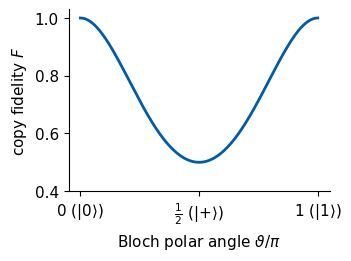

In [2]:
for b, k in [(0, ket0), (1, ket1)]:
    assert np.allclose(CNOT @ np.kron(k, ket0), np.kron(k, k))          # basis states are copied
out_plus = CNOT @ np.kron(plus, ket0)
F_plus = abs(np.vdot(np.kron(plus, plus), out_plus)) ** 2
assert np.allclose(out_plus, phi_plus) and abs(F_plus - 0.5) < TOL     # |+> becomes the Bell state
print(f"CNOT copier: output for |+> is the Bell state, fidelity with |+>|+> = {F_plus:.2f}")

# the linear map L with L|0> = |00>, L|+> = |++> : columns L|0>, L|1> from linearity
L = np.zeros((4, 2), dtype=complex)
L[:, 0] = np.kron(ket0, ket0)
L[:, 1] = np.sqrt(2) * np.kron(plus, plus) - np.kron(ket0, ket0)        # |1> = sqrt2 |+> - |0>
assert np.allclose(L @ plus, np.kron(plus, plus))
G = L.conj().T @ L
assert not np.allclose(G, np.eye(2))                                     # not an isometry
assert abs(np.vdot(ket0, plus) - np.vdot(L @ ket0, L @ plus)) > 0.2      # overlap 1/sqrt2 becomes 1/2
assert not np.allclose(L @ ket1, np.kron(ket1, ket1))                    # and |1> is not copied
print("L^dagger L =\n", np.round(G.real, 3))
print(f"<0|+> = {np.vdot(ket0, plus).real:.3f}, but <00|++> = {np.vdot(L @ ket0, L @ plus).real:.3f}")

# fidelity of the CNOT copier on the meridian cos(t/2)|0> + sin(t/2)|1>
theta = np.linspace(0, np.pi, 201)
F_clone = np.array([abs(np.vdot(np.kron(v, v), CNOT @ np.kron(v, ket0))) ** 2
                    for v in (np.array([np.cos(t / 2), np.sin(t / 2)]) for t in theta)])
assert np.allclose(F_clone, (np.cos(theta / 2) ** 3 + np.sin(theta / 2) ** 3) ** 2)
NUMBERS["FidCNOTPlus"] = f"{F_plus:.2f}"

def panel_clone(ax):
    ax.plot(theta / np.pi, F_clone, color=BLUE, lw=2)
    ax.set_xlabel(r"Bloch polar angle $\vartheta/\pi$"); ax.set_ylabel(r"copy fidelity $F$")
    ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels([r"0 $(|0\rangle)$", r"$\frac{1}{2}$ $(|{+}\rangle)$", r"1 $(|1\rangle)$"])
    ax.set_ylim(0.4, 1.03)
make_figures("cloning", [panel_clone], notes_size=(3.4, 2.5))

The copy fidelity equals one at $|0\rangle$ and $|1\rangle$, the two states the CNOT gate was built to copy, and falls to $1/2$ at $|{+}\rangle$ on the meridian of the figure, where the output is the entangled Bell state. For $|{-}\rangle$ it vanishes. Any other copier chosen to copy two other orthogonal states fails in the same way on their superpositions. Measuring a state destroys it, and no copy can be made for a measurement in another basis, so learning an unknown state requires many fresh preparations of it.

## 2. Telling two states apart with one copy

A source emits one copy of either $\hat\rho$ or $\hat\sigma$, each with probability one half, and we must guess which. A guessing rule is a two-outcome measurement with POVM elements $\hat\Pi$ and $\hat I-\hat\Pi$, where $0\le\hat\Pi\le\hat I$, and we answer $\hat\rho$ on the first outcome. The probability of a correct guess is
$$P_{\rm succ}=\tfrac12\mathrm{Tr}(\hat\Pi\hat\rho)+\tfrac12\mathrm{Tr}\big[(\hat I-\hat\Pi)\hat\sigma\big]=\tfrac12+\tfrac12\mathrm{Tr}\big[\hat\Pi(\hat\rho-\hat\sigma)\big]. \tag{3}$$
We write $\hat\rho-\hat\sigma=\sum_k\mu_k|k\rangle\langle k|$. The trace $\mathrm{Tr}[\hat\Pi(\hat\rho-\hat\sigma)]=\sum_k\mu_k\langle k|\hat\Pi|k\rangle$ is largest when $\langle k|\hat\Pi|k\rangle=1$ for every positive $\mu_k$ and $0$ for every negative one, that is, when $\hat\Pi$ is the projector on the positive part of $\hat\rho-\hat\sigma$. The sum of the positive eigenvalues is the trace distance $D(\hat\rho,\hat\sigma)=\frac12\sum_k|\mu_k|$, and the best success probability is the Helstrom result
$$P_{\rm succ}^{\max}=\tfrac12\big[1+D(\hat\rho,\hat\sigma)\big]. \tag{4}$$
For two pure states $D=\sqrt{1-|\langle\varphi|\psi\rangle|^2}$, so only orthogonal states are told apart with certainty. This derives the success probability $\frac12(1+D)$ quoted with the trace distance. For $|0\rangle$ and $|{+}\rangle$ a $\hat Z$ measurement succeeds with probability $3/4$, and the optimal measurement is along the Bloch direction of $\mathbf r_\rho-\mathbf r_\sigma\propto(\mathbf e_z-\mathbf e_x)$, with the unit vectors $\mathbf e_x$, $\mathbf e_z$ of the Bloch sphere.

|0> vs |+>: Helstrom P = 0.854, Z measurement P = 0.750, optimal axis [-0.707  0.     0.707]


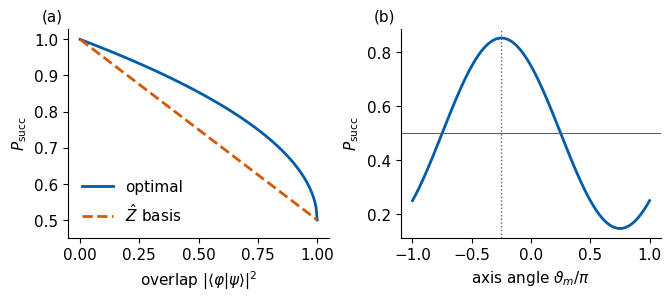

In [3]:
def helstrom(rho, sigma):
    mu, V = np.linalg.eigh(rho - sigma)
    Pi = V[:, mu > 0] @ V[:, mu > 0].conj().T                    # projector on the positive part
    p_meas = 0.5 + 0.5 * np.real(np.trace(Pi @ (rho - sigma)))
    return p_meas, 0.5 * (1 + 0.5 * np.sum(np.abs(mu))), Pi

def random_povm_element(d):
    # a random 0 <= Pi <= 1: a Haar unitary times random eigenvalues in [0, 1]
    U = haar_unitary(d)
    return U @ np.diag(rng.uniform(0, 1, d)) @ U.conj().T

rho0, rhop = dm(ket0), dm(plus)
p_opt, p_formula, Pi_opt = helstrom(rho0, rhop)
assert abs(p_opt - p_formula) < TOL
assert abs(p_opt - 0.5 * (1 + np.sqrt(1 - abs(np.vdot(ket0, plus)) ** 2))) < TOL
p_Z = 0.5 * np.real(np.trace(dm(ket0) @ rho0)) + 0.5 * np.real(np.trace(dm(ket1) @ rhop))
assert abs(p_Z - 0.75) < TOL
m_opt = np.real([np.trace(Pi_opt @ P) for P in (X, Y, Z)])                 # Bloch axis of the optimal projector
assert np.allclose(m_opt / np.linalg.norm(m_opt), np.array([-1, 0, 1]) / np.sqrt(2))
print(f"|0> vs |+>: Helstrom P = {p_opt:.3f}, Z measurement P = {p_Z:.3f}, optimal axis {np.round(m_opt / np.linalg.norm(m_opt), 3)}")

# no measurement does better: random POVM elements for random mixed states of one and two qubits
for d in (2, 4):
    for _ in range(200):
        A = haar_states(d, 3); w = rng.dirichlet(np.ones(3))
        r = sum(wi * dm(a) for wi, a in zip(w, A))
        B = haar_states(d, 2); s = 0.5 * dm(B[0]) + 0.5 * dm(B[1])
        best = helstrom(r, s)[0]
        Pi = random_povm_element(d)
        assert 0.5 + 0.5 * np.real(np.trace(Pi @ (r - s))) <= best + TOL
# small perturbations of the optimal projector, clipped back to 0 <= Pi <= 1, never do better
for _ in range(200):
    Hp = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)); Hp = (Hp + Hp.conj().T) / 2
    w_, V_ = np.linalg.eigh(Pi_opt + 0.05 * Hp)
    Pi_p = (V_ * np.clip(w_, 0, 1)) @ V_.conj().T
    assert 0.5 + 0.5 * np.real(np.trace(Pi_p @ (rho0 - rhop))) <= p_opt + TOL
NUMBERS["HelstromZeroPlus"] = f"{p_opt:.2f}"

F_grid = np.linspace(0, 1, 201)
P_hel = 0.5 * (1 + np.sqrt(1 - F_grid))
P_zmeas = 1 - F_grid / 2              # |0> vs a state with overlap F, measured in Z
phi = np.linspace(-np.pi, np.pi, 361)
P_axis = 0.5 + 0.25 * (np.cos(phi) - np.sin(phi))   # projector along (sin phi, 0, cos phi) for |0> vs |+>
assert abs(P_axis.max() - p_opt) < 1e-4

def panel_hel_a(ax):
    ax.plot(F_grid, P_hel, color=BLUE, lw=2, label="optimal")
    ax.plot(F_grid, P_zmeas, color=ORANGE, lw=2, ls="--", label=r"$\hat Z$ basis")
    ax.set_xlabel(r"overlap $|\langle\varphi|\psi\rangle|^2$"); ax.set_ylabel(r"$P_{\rm succ}$")
    ax.set_ylim(0.45, 1.03); ax.legend(frameon=False, loc="lower left")
def panel_hel_b(ax):
    ax.plot(phi / np.pi, P_axis, color=BLUE, lw=2)
    ax.axvline(-0.25, color=GRAY, ls=":", lw=1)
    ax.axhline(0.5, color=GRAY, lw=0.8)
    ax.set_xlabel(r"axis angle $\vartheta_m/\pi$"); ax.set_ylabel(r"$P_{\rm succ}$")
make_figures("helstrom", [panel_hel_a, panel_hel_b])

In panel (a) the optimal measurement beats the $\hat Z$ measurement for every overlap between $0$ and $1$, and both reach certainty only for orthogonal states. Panel (b) scans projective measurements along the axis $(\sin\vartheta_m,0,\cos\vartheta_m)$ of the Bloch sphere for $|0\rangle$ against $|{+}\rangle$. The success probability is largest at $\vartheta_m=-\pi/4$ (dotted), the direction of $\mathbf e_z-\mathbf e_x$, and the $\hat Z$ basis at $\vartheta_m=0$ gives $3/4$. The thin line marks the random guess $1/2$. Two non-orthogonal states can never be distinguished with certainty from one copy, which is the measurement side of the no-cloning theorem.

## 3. How many bits $N$ qubits carry

A sender encodes a classical message $x$, chosen with probability $p_x$, in a state $\hat\rho_x$ and sends it to a receiver, who measures. The receiver's average state is $\hat{\bar\rho}=\sum_xp_x\hat\rho_x$. The Holevo quantity
$$\chi=S(\hat{\bar\rho})-\sum_xp_x\,S(\hat\rho_x) \tag{5}$$
bounds the mutual information between $x$ and the outcome of any measurement, the reduction in bits of the Shannon entropy of $x$ upon learning the outcome, and since $S(\hat{\bar\rho})\le\log_2 2^N=N$,
$$I(x{:}\text{outcome})\le\chi\le N\ \text{bits}. \tag{6}$$
The $2^N$ amplitudes of $N$ qubits are therefore not a store of $2^N$ readable numbers. However many different states the sender uses, a receiver who shares no entanglement with the sender learns at most $N$ bits per register.

For two pure states with equal probabilities and the Bloch angle $\alpha$ between them, $|0\rangle$ and $\cos\frac\alpha2|0\rangle+\sin\frac\alpha2|1\rangle$, the average state has the eigenvalues $\frac12(1\pm\cos\frac\alpha2)$ and $\chi=S_{\rm bin}\big(\frac12(1+\cos\frac\alpha2)\big)$, with the binary entropy $S_{\rm bin}(p)=-p\log_2p-(1-p)\log_2(1-p)$. The Helstrom measurement of Section 2 errs with the probability $p_{\rm err}=\frac12(1-\sin\frac\alpha2)$ for either message, so its outcome leaves $S_{\rm bin}(p_{\rm err})$ of the one bit of uncertainty and carries $1-S_{\rm bin}(p_{\rm err})$ bits about $x$.

|0>, |+>: chi = 0.601 bit, Helstrom measurement extracts 0.399 bit


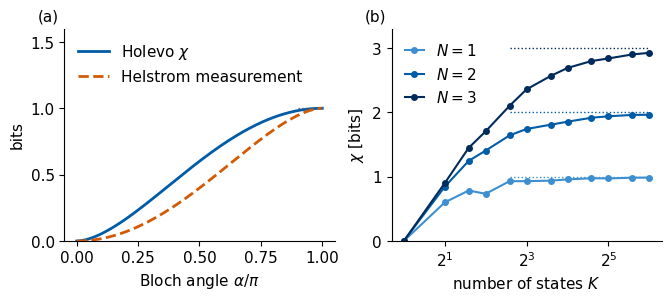

In [4]:
def S_bin(p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -p * np.log2(p) - (1 - p) * np.log2(1 - p)

def holevo(ps, rhos):
    rbar = sum(p * r for p, r in zip(ps, rhos))
    return entropy_bits(rbar) - sum(p * entropy_bits(r) for p, r in zip(ps, rhos))

alpha = np.linspace(0, np.pi, 181)
chi = np.array([holevo([0.5, 0.5], [dm(ket0), dm(np.array([np.cos(a / 2), np.sin(a / 2)]))]) for a in alpha])
assert np.allclose(chi, S_bin(0.5 * (1 + np.cos(alpha / 2))), atol=1e-9)
I_hel = 1 - S_bin(0.5 * (1 - np.sin(alpha / 2)))
assert np.all(I_hel <= chi + 1e-9)
chi_half = holevo([0.5, 0.5], [dm(ket0), dm(plus)])
NUMBERS["HolevoZeroPlus"] = f"{chi_half:.2f}"
NUMBERS["HelstromInfoZeroPlus"] = f"{1 - S_bin(0.5 * (1 - np.sin(np.pi / 4))):.2f}"
print(f"|0>, |+>: chi = {chi_half:.3f} bit, Helstrom measurement extracts {1 - S_bin(0.5 * (1 - np.sin(np.pi / 4))):.3f} bit")

# many random pure states on N qubits: chi grows with their number K but never exceeds N
Ks = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64])
chi_K = {}
for N in (1, 2, 3):
    d = 2 ** N
    vals = []
    for K in Ks:
        draws = [holevo(np.ones(K) / K, [dm(v) for v in haar_states(d, K)]) for _ in range(5)]
        assert max(draws) <= N + 1e-9 and max(draws) <= np.log2(K) + 1e-9
        vals.append(np.mean(draws))
    chi_K[N] = np.array(vals)
NUMBERS["HolevoKmaxNThree"] = f"{chi_K[3][-1]:.2f}"

def panel_hol_a(ax):
    ax.plot(alpha / np.pi, chi, color=BLUE, lw=2, label=r"Holevo $\chi$")
    ax.plot(alpha / np.pi, I_hel, color=ORANGE, lw=2, ls="--", label="Helstrom measurement")
    ax.hlines(1, 0.9, 1, color=GRAY, ls=":", lw=1)
    ax.set_xlabel(r"Bloch angle $\alpha/\pi$"); ax.set_ylabel("bits"); ax.set_ylim(0, 1.6)
    ax.legend(frameon=False, loc="upper left")
def panel_hol_b(ax):
    for N, c in zip((1, 2, 3), (SKY, BLUE, NAVY)):
        ax.plot(Ks, chi_K[N], "o-", color=c, ms=4, lw=1.5, label=f"$N={N}$")
        ax.hlines(N, 6, 64, color=c, ls=":", lw=1)
    ax.set_xscale("log", base=2); ax.set_xlabel(r"number of states $K$"); ax.set_ylabel(r"$\chi$ [bits]")
    ax.set_ylim(0, 3.3); ax.legend(frameon=False, loc="upper left", handlelength=1.2)
make_figures("holevo", [panel_hol_a, panel_hol_b])

Panel (a) shows that two states at a small Bloch angle carry little information, since even the optimal guess is nearly random. At $\alpha=\pi$ they are orthogonal and carry one bit. The Helstrom measurement stays below $\chi$ between these limits. In panel (b) a sender uses $K$ random pure states of $N$ qubits with equal probabilities. The Holevo quantity grows with $K$ and saturates below the dotted line at $N$ bits, however many states, and hence however many continuous amplitudes, are used.

## 4. Universality and the cost of a general unitary

CNOT gates and single-qubit rotations are universal, so every unitary on $N$ qubits decomposes into a circuit of these gates. The decomposition proceeds through controlled single-qubit gates, and Section 4.1 constructs such a gate explicitly. Counting parameters shows that a general unitary is expensive. A unitary $2^N\times2^N$ matrix has $4^N$ real parameters, one of them an unobservable global phase. A two-qubit gate has at most $4^2-1=15$ parameters, and single-qubit gates can be absorbed into the neighbouring two-qubit gates, so a circuit of $G$ two-qubit gates can reach a generic unitary only if
$$15\,G\ \ge\ 4^N-1 . \tag{7}$$

### 4.1 A controlled gate from CNOT gates and rotations (optional)

Every single-qubit gate is a rotation, $\hat U=e^{i\eta}\hat R_z(\theta_1)\hat R_y(\theta_2)\hat R_z(\theta_3)$ with the global phase $\eta$ (Euler decomposition). A controlled-$\hat U$ gate, which applies $\hat U$ to qubit 1 when qubit 0 is in $|1\rangle$, then follows from two CNOT gates and three rotations. With
$$\hat A=\hat R_z(\theta_1)\hat R_y(\tfrac{\theta_2}2),\qquad \hat B=\hat R_y(-\tfrac{\theta_2}2)\hat R_z(-\tfrac{\theta_3+\theta_1}2),\qquad \hat C=\hat R_z(\tfrac{\theta_3-\theta_1}2), \tag{8}$$
one has $\hat A\hat B\hat C=\hat I$ and $\hat A\hat X\hat B\hat X\hat C=e^{-i\eta}\hat U$, because $\hat X$ on both sides of $\hat B$ reverses its angles. When qubit 0 is $|0\rangle$ the CNOT gates do nothing and qubit 1 receives $\hat A\hat B\hat C=\hat I$. When it is $|1\rangle$ both CNOT gates act as $\hat X$ and qubit 1 receives $e^{-i\eta}\hat U$. The phase gate $\mathrm{diag}(1,e^{i\eta})=e^{i\eta/2}\hat R_z(\eta)$ on qubit 0 restores the phase, so
$$\text{controlled-}\hat U=\big[\mathrm{diag}(1,e^{i\eta})\otimes\hat I\big]\,(\hat I\otimes\hat A)\,\widehat{\mathrm{CNOT}}\,(\hat I\otimes\hat B)\,\widehat{\mathrm{CNOT}}\,(\hat I\otimes\hat C). \tag{9}$$
Multi-controlled gates and finally every unitary on $N$ qubits decompose in the same spirit into CNOT gates and single-qubit rotations.

controlled-U from two CNOTs and rotations: checked for 50 random U
N =  2: 4^N - 1 = 15 parameters, at least 1 two-qubit gates
N =  5: 4^N - 1 = 1.02e+03 parameters, at least 69 two-qubit gates
N = 10: 4^N - 1 = 1.05e+06 parameters, at least 6.99e+04 two-qubit gates
N = 20: 4^N - 1 = 1.1e+12 parameters, at least 7.33e+10 two-qubit gates


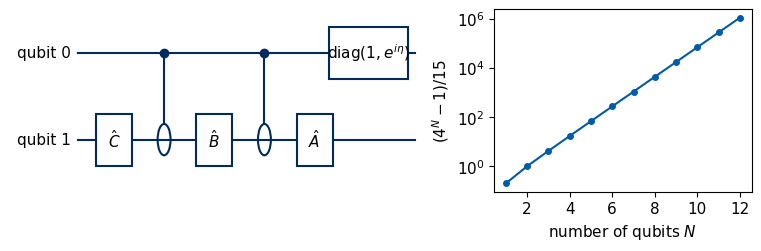

In [5]:
def Rz(a): return np.diag([np.exp(-1j * a / 2), np.exp(1j * a / 2)])
def Ry(a): return np.array([[np.cos(a / 2), -np.sin(a / 2)], [np.sin(a / 2), np.cos(a / 2)]], dtype=complex)

def euler_zyz(U):
    # U = e^{i eta} Rz(t1) Ry(t2) Rz(t3)
    eta = np.angle(np.linalg.det(U)) / 2
    V = U * np.exp(-1j * eta)
    t2 = 2 * np.arctan2(abs(V[1, 0]), abs(V[0, 0]))
    s_ = -2 * np.angle(V[0, 0]); d_ = 2 * np.angle(V[1, 0])          # t1 + t3 and t1 - t3
    t1, t3 = (s_ + d_) / 2, (s_ - d_) / 2
    if not np.allclose(np.exp(1j * eta) * Rz(t1) @ Ry(t2) @ Rz(t3), U):
        eta += np.pi                                                 # the other square root of the determinant
        V = U * np.exp(-1j * eta)
        s_ = -2 * np.angle(V[0, 0]); d_ = 2 * np.angle(V[1, 0]); t1, t3 = (s_ + d_) / 2, (s_ - d_) / 2
    return eta, t1, t2, t3

for _ in range(50):
    U = haar_unitary(2)
    eta, t1, t2, t3 = euler_zyz(U)
    assert np.allclose(np.exp(1j * eta) * Rz(t1) @ Ry(t2) @ Rz(t3), U)
    A, B, C = Rz(t1) @ Ry(t2 / 2), Ry(-t2 / 2) @ Rz(-(t3 + t1) / 2), Rz((t3 - t1) / 2)
    assert np.allclose(A @ B @ C, I2) and np.allclose(A @ X @ B @ X @ C, np.exp(-1j * eta) * U)
    assert np.allclose(np.diag([1, np.exp(1j * eta)]), np.exp(1j * eta / 2) * Rz(eta))
    circuit = np.kron(np.diag([1, np.exp(1j * eta)]), I2) @ np.kron(I2, A) @ CNOT @ np.kron(I2, B) @ CNOT @ np.kron(I2, C)
    target = np.kron(dm(ket0), I2) + np.kron(dm(ket1), U)
    assert np.allclose(circuit, target)
print("controlled-U from two CNOTs and rotations: checked for 50 random U")

for N in (2, 5, 10, 20):
    print(f"N = {N:2d}: 4^N - 1 = {4 ** N - 1:.3g} parameters, at least {int(np.ceil((4 ** N - 1) / 15)):.3g} two-qubit gates")
NUMBERS["GatesBoundTen"] = f"{int(np.ceil((4 ** 10 - 1) / 15))}"

# a picture of circuit (9) and of the gate bound (7)
def draw_controlled_u(ax):
    for y in (1, 0):
        ax.plot([0, 9.4], [y, y], color=NAVY, lw=1.5, zorder=1)
    def box(x, y, lbl, w=1.0):
        ax.add_patch(plt.Rectangle((x - w / 2, y - 0.3), w, 0.6, fc="white", ec=NAVY, lw=1.5, zorder=2))
        ax.text(x, y, lbl, ha="center", va="center", zorder=3)
    def cnot(x):
        ax.plot([x, x], [1, -0.18], color=NAVY, lw=1.5, zorder=1); ax.plot(x, 1, "o", color=NAVY, ms=6, zorder=3)
        ax.add_patch(plt.Circle((x, 0), 0.18, fc="white", ec=NAVY, lw=1.5, zorder=2)); ax.plot([x - 0.18, x + 0.18], [0, 0], color=NAVY, lw=1.5, zorder=3)
    box(1.0, 0, r"$\hat C$"); cnot(2.4); box(3.8, 0, r"$\hat B$"); cnot(5.2); box(6.6, 0, r"$\hat A$")
    box(8.1, 1, r"diag$(1,e^{i\eta})$", w=2.2)
    ax.text(-0.2, 1, "qubit 0", ha="right", va="center"); ax.text(-0.2, 0, "qubit 1", ha="right", va="center")
    ax.set_xlim(-1.9, 9.6); ax.set_ylim(-0.6, 1.5); ax.axis("off")
def panel_gate_bound(ax):
    NN = np.arange(1, 13)
    ax.semilogy(NN, (4.0 ** NN - 1) / 15, "o-", color=BLUE, ms=4)
    ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(r"$(4^N-1)/15$")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
with plt.rc_context({"font.size": 11}):
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.4), gridspec_kw={"width_ratios": [1.6, 1]}, constrained_layout=True)
    draw_controlled_u(axes[0]); panel_gate_bound(axes[1])
    plt.show()

The left drawing shows circuit (9), read from left to right, and the decomposition holds for every random $\hat U$, so CNOT and rotations produce every controlled gate. The counting bound (7), plotted on the right, grows as $4^N$, and already for ten qubits a generic unitary needs tens of thousands of two-qubit gates. Useful circuits are therefore special, short circuits that reach only a tiny part of all unitaries.

## 5. Clifford gates and Pauli strings

Conjugating a Pauli string by $\hat H$, $\hat S$ or CNOT gives again a Pauli string, up to a sign,
$$\hat H\hat X\hat H=\hat Z,\quad \hat H\hat Z\hat H=\hat X,\quad \hat S\hat X\hat S^\dagger=\hat Y,\quad \hat S\hat Z\hat S^\dagger=\hat Z,\quad \widehat{\mathrm{CNOT}}\,\hat X_0\,\widehat{\mathrm{CNOT}}=\hat X_0\hat X_1,\quad \widehat{\mathrm{CNOT}}\,\hat Z_1\,\widehat{\mathrm{CNOT}}=\hat Z_0\hat Z_1, \tag{10}$$
with $\hat Z_0$ and $\hat X_1$ unchanged by CNOT. Unitaries with this property are called Clifford gates, and $\hat H$, $\hat S$ and CNOT generate all of them. A Pauli string on $N$ qubits is stored by $2N$ bits and a sign. Qubit $q$ carries $(x_q,z_q)=(0,0),(1,0),(0,1),(1,1)$ for $\hat I,\hat X,\hat Z,\hat Y$. Each gate then updates a few bits, so following one Pauli string through a circuit of $G$ gates costs about $G$ bit operations and following all $N$ stabilisers about $NG$, whereas a dense simulation multiplies $2^N\times2^N$ matrices.

A Pauli string $\hat P$ stabilises a state $|\psi\rangle$ if $\hat P|\psi\rangle=|\psi\rangle$, and $|0\dots0\rangle$ is stabilised by $\hat Z_0,\dots,\hat Z_{N-1}$. A Clifford circuit $\hat V$ maps them to the stabilisers $\hat V\hat Z_q\hat V^\dagger$ of $\hat V|0\dots0\rangle$, and such states are called stabiliser states. The expectation value of a Pauli string $\hat P$ in the state $\hat V|0\dots0\rangle$ is $\langle0\dots0|\hat V^\dagger\hat P\hat V|0\dots0\rangle$, where $\hat V^\dagger\hat P\hat V=\pm\hat Q$ is again a Pauli string. Its value is $\pm1$ when $\hat Q$ contains only $\hat Z$ and $\hat I$ factors and $0$ otherwise. Clifford circuits acting on $|0\dots0\rangle$ and followed by Pauli measurements can therefore be simulated efficiently on a classical computer, which is the Gottesman–Knill theorem. The $\hat T$ gate maps $\hat X$ to $(\hat X+\hat Y)/\sqrt2$, which is not a Pauli string, and adding it to the Clifford gates gives a universal set.

In [6]:
class PauliString:
    # sign * P_0 (x) ... (x) P_{N-1}, with (x_q, z_q) = (0,0) I, (1,0) X, (0,1) Z, (1,1) Y
    def __init__(self, label, sign=1):
        self.x = np.array([c in "XY" for c in label], dtype=bool)
        self.z = np.array([c in "ZY" for c in label], dtype=bool)
        self.sign = sign
    def label(self):
        return "".join("IXZY"[int(a) + 2 * int(b)] for a, b in zip(self.x, self.z))
    def matrix(self):
        return self.sign * pauli_string(self.label())
    # conjugation P -> G P G^dagger by one gate
    def H(self, q):
        if self.x[q] and self.z[q]: self.sign *= -1
        self.x[q], self.z[q] = self.z[q], self.x[q]
    def S(self, q):
        if self.x[q] and self.z[q]: self.sign *= -1
        self.z[q] ^= self.x[q]
    def Sdg(self, q):
        if self.x[q] and not self.z[q]: self.sign *= -1
        self.z[q] ^= self.x[q]
    def CNOT(self, c, t):
        if self.x[c] and self.z[t] and (self.x[t] == self.z[c]): self.sign *= -1
        self.x[t] ^= self.x[c]; self.z[c] ^= self.z[t]

def gate_matrix(name, qs, N):
    if name == "CNOT":
        c, t = qs
        P0 = [I2] * N; P0[c] = dm(ket0)
        P1 = [I2] * N; P1[c] = dm(ket1); P1[t] = X
        return kron_all(*P0) + kron_all(*P1)
    ops = [I2] * N; ops[qs[0]] = {"H": H, "S": S, "Sdg": S.conj().T}[name]
    return kron_all(*ops)

# the conjugation rules (10) agree with dense matrices for random circuits and random Pauli strings
N = 3
for trial in range(100):
    P = PauliString("".join(rng.choice(list("IXYZ"), N)))
    M = P.matrix()
    for _ in range(12):
        g = rng.choice(["H", "S", "Sdg", "CNOT"])
        qs = tuple(rng.choice(N, 2, replace=False)) if g == "CNOT" else (int(rng.integers(N)),)
        getattr(P, g)(*qs)
        Gm = gate_matrix(g, qs, N)
        M = Gm @ M @ Gm.conj().T
    assert np.allclose(P.matrix(), M)
print("Pauli propagation agrees with dense conjugation in 100 random Clifford circuits")

# stabilisers of the GHZ state: propagate Z_q through H_0, CNOT_{0->1}, CNOT_{1->2}, ...
def ghz_stabilisers(N):
    gens = [PauliString("I" * q + "Z" + "I" * (N - q - 1)) for q in range(N)]
    for P in gens:
        P.H(0)
        for q in range(N - 1):
            P.CNOT(q, q + 1)
    return gens
gens4 = ghz_stabilisers(4)
print("GHZ_4 stabilisers:", [("+" if P.sign > 0 else "-") + P.label() for P in gens4])
ghz4 = np.zeros(16, dtype=complex); ghz4[0] = ghz4[-1] = 1 / np.sqrt(2)
for P in gens4:
    assert np.allclose(P.matrix() @ ghz4, ghz4)
bell = ghz_stabilisers(2)
assert sorted(P.label() for P in bell) == ["XX", "ZZ"]
for N_ in (3, 4, 6):                       # generators after the circuit: X...X and Z_{q-1} Z_q for q >= 1, all with sign +
    g_ = ghz_stabilisers(N_)
    assert g_[0].label() == "X" * N_ and g_[0].sign == 1
    for q in range(1, N_):
        assert g_[q].label() == "I" * (q - 1) + "ZZ" + "I" * (N_ - q - 1) and g_[q].sign == 1

# the columns of the stabiliser table for GHZ_3, gate by gate
cols = [[PauliString("I" * q + "Z" + "I" * (2 - q)) for q in range(3)]]
steps = [("H", (0,)), ("CNOT", (0, 1)), ("CNOT", (1, 2))]
cur = [PauliString("I" * q + "Z" + "I" * (2 - q)) for q in range(3)]
for g, qs in steps:
    for P in cur:
        getattr(P, g)(*qs)
    cols.append([PauliString(P.label(), P.sign) for P in cur])
print("stabilisers of |000> through H_0, CNOT_01, CNOT_12:")
for row in range(3):
    print("   ".join(c[row].label() for c in cols))

t0 = time.perf_counter(); gens = ghz_stabilisers(1000); t_big = time.perf_counter() - t0
assert gens[0].label() == "X" * 1000
print(f"GHZ stabilisers of 1000 qubits from the bit update in {t_big:.2f} s; a state vector would need 2^1000 amplitudes")

# T leaves the Pauli group
TXT = T @ X @ T.conj().T
assert np.allclose(TXT, (X + Y) / np.sqrt(2))
assert all(not np.allclose(TXT, s * P) for P in (I2, X, Y, Z) for s in (1, -1))

Pauli propagation agrees with dense conjugation in 100 random Clifford circuits
GHZ_4 stabilisers: ['+XXXX', '+ZZII', '+IZZI', '+IIZZ']
stabilisers of |000> through H_0, CNOT_01, CNOT_12:
ZII   XII   XXI   XXX
IZI   IZI   ZZI   ZZI
IIZ   IIZ   IIZ   IZZ
GHZ stabilisers of 1000 qubits from the bit update in 0.51 s; a state vector would need 2^1000 amplitudes


The bit update reproduces the dense conjugation in every random circuit. The GHZ circuit maps the stabilisers $\hat Z_q$ of $|0000\rangle$ to $\hat X_0\hat X_1\hat X_2\hat X_3$, $\hat Z_0\hat Z_1$, $\hat Z_1\hat Z_2$ and $\hat Z_2\hat Z_3$, and for two qubits the Bell state is stabilised by $\hat X\hat X$ and $\hat Z\hat Z$, the two parities that are certain in its measurement records. The same update describes a thousand-qubit GHZ circuit in a fraction of a second, although its state vector could never be stored. Entanglement alone therefore does not make a circuit hard to simulate. The $\hat T$ gate leaves the set of Pauli strings and breaks this shortcut.

## 6. Random states, concentration and 2-designs

A uniformly random, or Haar-random, state of $N$ qubits is a unit vector drawn so that every unitary $\hat U$ leaves its distribution unchanged, $\hat U|\psi\rangle$ being as random as $|\psi\rangle$. We sample it by normalising a vector of $d=2^N$ independent complex Gaussian numbers. Since gates such as $\hat X_q$ permute the basis states, every bit string $b$ has the same average probability, and the probabilities sum to one,
$$\mathbb E\,|\langle b|\psi\rangle|^2=\frac1{2^N}. \tag{11}$$
The $4^N$ Pauli strings are orthogonal, $\mathrm{Tr}(\hat P\hat Q)=2^N\delta_{PQ}$, so every state has the expansion $\hat\rho=\frac1d\sum_{\hat P}\langle\hat P\rangle\hat P$ and the purity $\mathrm{Tr}\hat\rho^2=\frac1d\sum_{\hat P}\langle\hat P\rangle^2$, which is one for a pure state. With $\langle\hat I\rangle=1$ the $d^2-1$ other strings share $\sum_{\hat P\ne\hat I}\langle\hat P\rangle^2=d-1$. For any two non-identity strings there is a Clifford gate that maps one to the other up to a sign, so for a Haar-random state each of them has the same average of $\langle\hat P\rangle^2$. A Pauli string that anticommutes with $\hat P$ maps $\hat P$ to $-\hat P$, so $\mathbb E\langle\hat P\rangle=0$ and
$$\mathrm{Var}\,\langle\hat P\rangle=\mathbb E\langle\hat P\rangle^2=\frac{d-1}{d^2-1}=\frac1{2^N+1}. \tag{12}$$
The expectation values of a random state concentrate at zero, with a spread that falls as $2^{-N/2}$, and a random state looks maximally mixed to every Pauli measurement.

### 6.1 Random Clifford circuits as a 2-design (optional)

Equations (11) and (12) use only the first and second moments of the random state. An ensemble of unitaries that reproduces the Haar averages of all polynomials of degree two in $\hat U$ and two in $\hat U^\dagger$ is a unitary 2-design. The Clifford group, drawn uniformly, is such an ensemble. A random stabiliser state has $\langle\hat P\rangle\in\{0,\pm1\}$, a very different distribution, yet its variance is also $1/(2^N+1)$. We check this with random Clifford circuits, propagated with the bit update of Section 5. A second test is the frame potential of an ensemble, the average of $|\mathrm{Tr}(\hat U^\dagger\hat W)|^4$ over pairs of its members. For a group it equals the average of $|\mathrm{Tr}\,\hat U|^4$ over single members, since $\hat U^\dagger\hat W$ runs through the group once for each $\hat U$. Its smallest possible value, $2$, is reached exactly by 2-designs.

N, Haar Var<Z0>, 1/(2^N+1):
 1  0.33429  0.33333
 2  0.19976  0.20000
 3  0.11545  0.11111
 4  0.06012  0.05882
 5  0.03022  0.03030
 6  0.01549  0.01538
 7  0.00814  0.00775
 8  0.00390  0.00389
 9  0.00200  0.00195
10  0.00094  0.00098
Clifford group sizes (modulo phase) and frame potentials: {1: (24, np.float64(1.9999999999999998)), 2: (11520, np.float64(1.999999999999998))}
frame potential of the 16 two-qubit Pauli strings: 16.0 (not a 2-design)


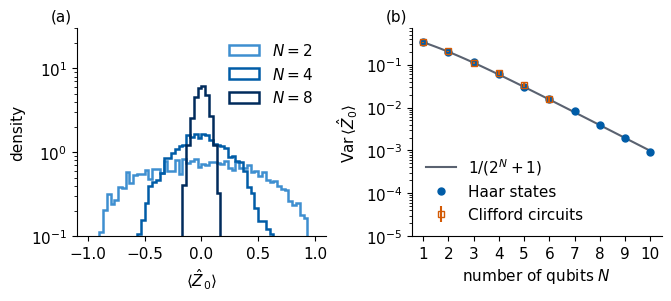

In [7]:
# Haar states: moments and concentration of <Z_0>
K_haar = 4000
Ns = np.arange(1, 11)
var_haar, ez0 = [], {}
for N in Ns:
    d = 2 ** N
    psi = haar_states(d, K_haar)
    p = np.abs(psi) ** 2
    z0 = p[:, : d // 2].sum(1) - p[:, d // 2:].sum(1)         # <Z_0>: qubit 0 is the most significant bit
    ez0[N] = z0
    var_haar.append(np.mean(z0 ** 2))
    se = np.std(p[:, 0]) / np.sqrt(K_haar)
    assert abs(p[:, 0].mean() - 1 / d) < 5 * se                # equation (11)
    se2 = np.std(z0 ** 2) / np.sqrt(K_haar)
    assert abs(np.mean(z0 ** 2) - 1 / (d + 1)) < 5 * se2      # equation (12)
var_haar = np.array(var_haar)
print("N, Haar Var<Z0>, 1/(2^N+1):")
for N, v in zip(Ns, var_haar):
    print(f"{N:2d}  {v:.5f}  {1 / (2 ** N + 1):.5f}")

# random Clifford circuits: Q = C^dagger Z_0 C from random H, S, S^dagger, CNOT (a set closed under inversion)
def clifford_z0_values(N, K, L):
    vals = np.empty(K)
    for k in range(K):
        P = PauliString("Z" + "I" * (N - 1))
        for _ in range(L):
            g = rng.integers(4)
            if g == 3 and N > 1:
                c, t = rng.choice(N, 2, replace=False); P.CNOT(c, t)
            else:
                q = int(rng.integers(N)); [P.H, P.S, P.Sdg, P.H][g](q)
        vals[k] = 0.0 if P.x.any() else P.sign               # <0...0|Q|0...0>
    return vals
Ns_cl = np.arange(1, 7)
var_cl, se_cl = [], []
for N in Ns_cl:
    v = clifford_z0_values(N, 2000, 6 * N * N + 20)
    assert set(np.unique(v)) <= {-1.0, 0.0, 1.0}
    var_cl.append(np.mean(v ** 2)); se_cl.append(np.std(v ** 2) / np.sqrt(len(v)))
    assert abs(var_cl[-1] - 1 / (2 ** N + 1)) < 5 * se_cl[-1]
var_cl = np.array(var_cl)

# frame potential over the full Clifford group of one and two qubits, generated from H, S, CNOT
def canon(U):
    k = np.argmax(np.abs(U.ravel()) > 1e-9)
    V = U * (abs(U.ravel()[k]) / U.ravel()[k])
    return (np.round(V.real, 8) + 0.0).tobytes() + (np.round(V.imag, 8) + 0.0).tobytes()
def clifford_group(N):
    gens = [gate_matrix("H", (q,), N) for q in range(N)] + [gate_matrix("S", (q,), N) for q in range(N)]
    if N == 2: gens.append(CNOT)
    start = np.eye(2 ** N, dtype=complex)
    seen = {canon(start): start}; frontier = [start]
    while frontier:
        new = []
        for U in frontier:
            for G_ in gens:
                V = G_ @ U; key = canon(V)
                if key not in seen:
                    seen[key] = V; new.append(V)
        frontier = new
    return list(seen.values())
frame = {}
for N in (1, 2):
    grp = clifford_group(N)
    frame[N] = (len(grp), np.mean([abs(np.trace(U)) ** 4 for U in grp]))
    assert abs(frame[N][1] - 2) < 1e-8
    Z0 = pauli_string("Z" + "I" * (N - 1))
    z0 = np.array([np.real(U[:, 0].conj() @ Z0 @ U[:, 0]) for U in grp])
    assert abs(np.mean(z0 ** 2) - 1 / (2 ** N + 1)) < 1e-10      # exact Clifford average equals (12)
print("Clifford group sizes (modulo phase) and frame potentials:", frame)
paulis2 = [pauli_string(a + b) for a in "IXYZ" for b in "IXYZ"]
print("frame potential of the 16 two-qubit Pauli strings:", np.mean([abs(np.trace(P)) ** 4 for P in paulis2]), "(not a 2-design)")
NUMBERS["CliffordGroupTwo"] = str(frame[2][0])
m_, e_ = f"{1 / (2 ** 10 + 1):.1e}".split("e")
NUMBERS["VarZTen"] = f"{m_}\\times10^{{{int(e_)}}}"

def panel_haar_a(ax):
    bins = np.linspace(-1, 1, 61)
    for N, c in zip((2, 4, 8), (SKY, BLUE, NAVY)):
        ax.hist(ez0[N], bins=bins, density=True, histtype="step", lw=1.8, color=c, label=f"$N={N}$")
    ax.set_xlabel(r"$\langle\hat Z_0\rangle$"); ax.set_ylabel("density"); ax.set_yscale("log"); ax.set_ylim(0.1, 30)
    ax.legend(frameon=False, loc="upper right")
def panel_haar_b(ax):
    NN = np.linspace(1, 10, 100)
    ax.plot(NN, 1 / (2 ** NN + 1), color=GRAY, lw=1.5, label=r"$1/(2^N+1)$")
    ax.plot(Ns, var_haar, "o", color=BLUE, ms=5, label="Haar states")
    ax.errorbar(Ns_cl, var_cl, yerr=se_cl, fmt="s", color=ORANGE, ms=4, mfc="none", label="Clifford circuits")
    ax.set_yscale("log"); ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(r"Var$\,\langle\hat Z_0\rangle$"); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_ylim(1e-5, 0.7); ax.legend(frameon=False, loc="lower left")
make_figures("haar", [panel_haar_a, panel_haar_b])

Panel (a) shows the distribution of $\langle\hat Z_0\rangle$ for Haar-random states. It spreads over the whole interval for two qubits and narrows quickly as $N$ grows, so a random state of eight qubits almost never shows a noticeable expectation value. In panel (b) the variance follows $1/(2^N+1)$ for Haar states and, within the statistical errors, for the states made by random Clifford circuits, although these take only the values $0$ and $\pm1$. The exact averages over the full Clifford groups of one and two qubits give the same variance and the frame potential $2$, while the Pauli strings alone give $16$ and are not a 2-design. Concentration of this kind makes the gradients of random parametrised circuits that are deep enough to behave like random unitaries vanish exponentially in $N$, and the 2-design property of random Clifford circuits underlies the classical shadows used to estimate many expectation values from few measurements. The core route ends with the concentration of Haar-random states, and the Clifford comparison of Section 6.1 is optional.

## 7. The Choi state of a channel

A noise channel $\mathcal E$ maps density matrices to density matrices, $\mathcal E(\hat\rho)=\sum_k\hat K_k\hat\rho\hat K_k^\dagger$ with Kraus operators $\hat K_k$ and $\sum_k\hat K_k^\dagger\hat K_k=\hat I$. Two examples are amplitude damping, with $\hat K_0=\mathrm{diag}(1,\sqrt{1-\gamma})$ and $\hat K_1=\sqrt\gamma\,|0\rangle\langle1|$, the decay of $|1\rangle$ to $|0\rangle$ with probability $\gamma$, and depolarising noise, with $\hat K_0=\sqrt{1-p}\,\hat I$ and $\hat K_{1,2,3}=\sqrt{p/3}\,\hat\sigma_a$, a random Pauli error with probability $p$. A channel can be measured by turning it into a state. We prepare the Bell state $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$, send qubit 0 through the channel and leave qubit 1 alone. The result is the Choi state
$$\hat\rho_{\mathcal E}=(\mathcal E\otimes\mathrm{id})\big(|\Phi^+\rangle\langle\Phi^+|\big)=\frac12\sum_{i,j}\mathcal E\big(|i\rangle\langle j|\big)\otimes|i\rangle\langle j|, \tag{13}$$
and state tomography of $\hat\rho_{\mathcal E}$ therefore measures the channel. Because the matrices $|i\rangle\langle j|$ form a basis, $\hat\rho_{\mathcal E}$ fixes the channel, $\mathcal E(\hat\rho)=2\,\mathrm{Tr}_1\big[\hat\rho_{\mathcal E}\,(\hat I\otimes\hat\rho^T)\big]$. The map preserves the trace if and only if $\mathrm{Tr}_0\hat\rho_{\mathcal E}=\hat I/2$, the trace over the output qubit 0. It is completely positive if and only if $\hat\rho_{\mathcal E}\ge0$. A completely positive map applied to qubit 0 of the Bell state gives a positive matrix, which shows one direction. For the other, the eigenvectors of $\hat\rho_{\mathcal E}=\sum_k\lambda_k|u_k\rangle\langle u_k|$, multiplied by $\sqrt{2\lambda_k}$ and reshaped to $2\times2$ matrices with qubit 0 labelling the rows, are Kraus operators, since $(\hat K\otimes\hat I)|\Phi^+\rangle=\frac1{\sqrt2}\sum_{a,i}K_{ai}|a\rangle|i\rangle$ is the matrix $K$ read row by row and divided by $\sqrt2$.

The transpose $\hat\rho\to\hat\rho^T$ keeps every eigenvalue of $\hat\rho$ and is therefore positive. Its Choi state $\frac12\sum_{ij}|j\rangle\langle i|\otimes|i\rangle\langle j|$ is half the SWAP gate, with the eigenvalue $-1/2$ on the singlet, so the transpose is not completely positive.

amplitude damping  Choi-state eigenvalues [0.85 0.15 0.   0.  ]
depolarising       Choi-state eigenvalues [0.7 0.1 0.1 0.1]
transpose          Choi-state eigenvalues [ 0.5  0.5  0.5 -0.5]


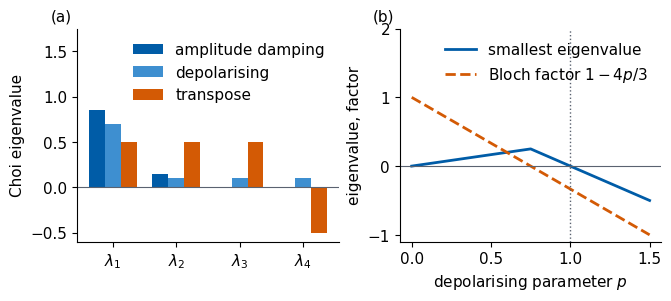

In [8]:
def channel_from_kraus(Ks):
    return lambda r: sum(K @ r @ K.conj().T for K in Ks)

def choi_state(channel, d=2):
    # (E x id)(|Phi+><Phi+|) = (1/d) sum_ij E(|i><j|) x |i><j|, channel on the first factor (qubit 0)
    R = np.zeros((d * d, d * d), dtype=complex)
    for i in range(d):
        for j in range(d):
            Eij = np.zeros((d, d), dtype=complex); Eij[i, j] = 1
            R += np.kron(channel(Eij), Eij) / d
    return R

def ptrace_out(R, d=2):     # trace over the first factor, the output of the channel
    return np.einsum("aiaj->ij", R.reshape(d, d, d, d))

def apply_from_choi(R, rho, d=2):
    M = d * R @ np.kron(np.eye(d), rho.T)
    return np.einsum("aibi->ab", M.reshape(d, d, d, d))

def kraus_from_choi(R, d=2):
    lam, V = np.linalg.eigh(R)
    return [np.sqrt(d * l) * V[:, k].reshape(d, d) for k, l in enumerate(lam) if l > 1e-12]

gamma, p_dep = 0.3, 0.3
amp_damp = channel_from_kraus([np.array([[1, 0], [0, np.sqrt(1 - gamma)]]), np.array([[0, np.sqrt(gamma)], [0, 0]])])
depol = channel_from_kraus([np.sqrt(1 - p_dep) * I2] + [np.sqrt(p_dep / 3) * P for P in (X, Y, Z)])
transpose = lambda r: r.T
maps = {"amplitude damping": amp_damp, "depolarising": depol, "transpose": transpose}
eig_choi = {}
for name, E in maps.items():
    Rc = choi_state(E)
    lam = np.linalg.eigvalsh(Rc)
    eig_choi[name] = lam[::-1]
    assert abs(np.trace(Rc).real - 1) < TOL and np.allclose(ptrace_out(Rc), I2 / 2)   # a unit-trace state, trace preserving
    for _ in range(20):
        v = haar_states(2, 1)[0]; r = dm(v)
        assert np.allclose(apply_from_choi(Rc, r), E(r))                    # the Choi state determines the channel
        if name != "transpose":
            assert np.allclose(channel_from_kraus(kraus_from_choi(Rc))(r), E(r))   # Kraus operators recovered
    print(f"{name:18s} Choi-state eigenvalues {np.round(lam[::-1], 3)}")
# the Choi state equals (E x id) applied to the Bell state
for E in (amp_damp, depol):
    Ks = [np.array([[1, 0], [0, np.sqrt(1 - gamma)]]), np.array([[0, np.sqrt(gamma)], [0, 0]])] if E is amp_damp else [np.sqrt(1 - p_dep) * I2] + [np.sqrt(p_dep / 3) * P for P in (X, Y, Z)]
    assert np.allclose(choi_state(E), sum(np.kron(K, I2) @ dm(phi_plus) @ np.kron(K, I2).conj().T for K in Ks))
assert np.allclose(choi_state(transpose), SWAP / 2) and abs(eig_choi["transpose"].min() + 0.5) < TOL
assert np.allclose(eig_choi["amplitude damping"], [1 - gamma / 2, gamma / 2, 0, 0])
assert np.allclose(eig_choi["depolarising"], [1 - p_dep] + [p_dep / 3] * 3)
# the Choi state of the depolarising channel is a Werner state with v = 1 - 4p/3
v_dep = 1 - 4 * p_dep / 3
assert np.allclose(choi_state(depol), v_dep * dm(phi_plus) + (1 - v_dep) * np.eye(4) / 4)
NUMBERS["ChoiAmpDampMax"] = f"{1 - gamma / 2:.2f}"

# the map rho -> (1-4p/3) rho + (4p/3) I/2 beyond p = 1: positive up to p = 3/2, completely positive only up to p = 1
pp = np.linspace(0, 1.5, 151)
lam_min = np.array([np.linalg.eigvalsh(choi_state(lambda r, p=p: (1 - 4 * p / 3) * r + (4 * p / 3) * np.trace(r) * I2 / 2)).min() for p in pp])
assert np.allclose(lam_min, np.minimum(1 - pp, pp / 3))

def panel_choi_a(ax):
    w = 0.25
    for k, (name, c) in enumerate(zip(maps, (BLUE, SKY, ORANGE))):
        ax.bar(np.arange(4) + (k - 1) * w, eig_choi[name], width=w, color=c, label=name)
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.set_xticks(range(4)); ax.set_xticklabels([r"$\lambda_1$", r"$\lambda_2$", r"$\lambda_3$", r"$\lambda_4$"])
    ax.set_ylabel("Choi eigenvalue"); ax.set_ylim(-0.6, 1.75); ax.legend(frameon=False, loc="upper right")
def panel_choi_b(ax):
    ax.plot(pp, lam_min, color=BLUE, lw=2, label="smallest eigenvalue")
    ax.plot(pp, 1 - 4 * pp / 3, color=ORANGE, lw=2, ls="--", label=r"Bloch factor $1-4p/3$")
    ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(1, color=GRAY, ls=":", lw=1)
    ax.set_xlabel(r"depolarising parameter $p$"); ax.set_ylabel("eigenvalue, factor"); ax.set_ylim(-1.1, 2.0)
    ax.legend(frameon=False, loc="upper right")
make_figures("choi", [panel_choi_a, panel_choi_b])

Panel (a) shows the four eigenvalues of each Choi state. Amplitude damping has two nonzero eigenvalues, $1-\gamma/2$ and $\gamma/2$, and hence two Kraus operators, the ones of the jump and no-jump branches. Depolarising noise has four, one for each Pauli error, and its Choi state is the mixture $v|\Phi^+\rangle\langle\Phi^+|+(1-v)\hat I/4$ with $v=1-\frac43p$. The transpose has the eigenvalue $-1/2$ and no Kraus form. Panel (b) continues the depolarising formula beyond $p=1$. The smallest eigenvalue starts at zero, because the identity channel at $p=0$ has the pure Choi state $|\Phi^+\rangle\langle\Phi^+|$ with three zero eigenvalues. The Bloch factor stays above $-1$ up to $p=3/2$, so every output is a density matrix, but the smallest eigenvalue of the Choi state becomes negative beyond $p=1$ (dotted), and the map is then positive without being completely positive.

## 8. Entanglement of mixed states and the partial transpose

A mixed state of two qubits is separable if it is a mixture of product states, $\hat\rho=\sum_kp_k\,\hat\rho_0^{(k)}\otimes\hat\rho_1^{(k)}$, and entangled otherwise. The correlated coin $\frac12(|00\rangle\langle00|+|11\rangle\langle11|)$, a source that emits $|00\rangle$ or $|11\rangle$ with probability one half, is separable, and the entropy of one qubit cannot tell it from the Bell state, since both give $\hat I/2$ on each qubit. The partial transpose transposes the indices of qubit 1 only,
$$\big(\hat\rho^{T_1}\big)_{ab,a'b'}=\rho_{ab',a'b}. \tag{14}$$
For a separable state $\hat\rho^{T_1}=\sum_kp_k\,\hat\rho_0^{(k)}\otimes\big(\hat\rho_1^{(k)}\big)^T$ is again a density matrix, because the transpose of a density matrix is one. A negative eigenvalue of $\hat\rho^{T_1}$ therefore proves entanglement (the Peres criterion), and for two qubits a positive partial transpose also proves separability (Horodecki). The negativity
$$\mathcal N(\hat\rho)=\tfrac12\big(\|\hat\rho^{T_1}\|_1-1\big), \tag{15}$$
the sum of the moduli of the negative eigenvalues, measures the entanglement. For the Werner state
$$\hat\rho_W=v\,|\Phi^+\rangle\langle\Phi^+|+(1-v)\,\frac{\hat I}4, \tag{16}$$
with the visibility $v$, the partial transpose of $|\Phi^+\rangle\langle\Phi^+|$ is $\widehat{\mathrm{SWAP}}/2$, and $\hat\rho_W^{T_1}$ has the eigenvalue $(1+v)/4$ three times and $(1-3v)/4$ once. The state is entangled if and only if $v>1/3$, with $\mathcal N=\max\big(0,\frac{3v-1}4\big)$.

Werner state entangled for v > 1/3; locally depolarised Bell state entangled for p < 0.317


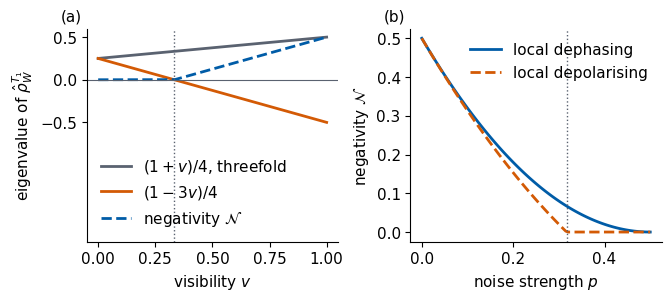

In [9]:
def ptranspose1(rho):
    return np.einsum("abcd->adcb", rho.reshape(2, 2, 2, 2)).reshape(4, 4)

# equation (14) checked against an explicit loop on a random, non-symmetric density matrix
A_ = rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)); rho_r = A_ @ A_.conj().T; rho_r /= np.trace(rho_r)
loop = np.zeros((4, 4), dtype=complex)
for a in range(2):
    for b in range(2):
        for a2 in range(2):
            for b2 in range(2):
                loop[2 * a + b, 2 * a2 + b2] = rho_r[2 * a + b2, 2 * a2 + b]
assert np.allclose(ptranspose1(rho_r), loop)

def negativity(rho):
    lam = np.linalg.eigvalsh(ptranspose1(rho))
    return float(-lam[lam < 0].sum())

def werner(v):
    return v * dm(phi_plus) + (1 - v) * np.eye(4) / 4

assert np.allclose(ptranspose1(dm(phi_plus)), SWAP / 2)
vs = np.linspace(0, 1, 201)
eig_w = np.array([np.linalg.eigvalsh(ptranspose1(werner(v))) for v in vs])
assert np.allclose(eig_w[:, 0], np.minimum((1 - 3 * vs) / 4, (1 + vs) / 4))
neg_w = np.array([negativity(werner(v)) for v in vs])
assert np.allclose(neg_w, np.maximum(0, (3 * vs - 1) / 4))
assert negativity(werner(1 / 3 + 1e-6)) > 0 and negativity(werner(1 / 3 - 1e-6)) == 0
# product states and their mixtures always have a positive partial transpose
for _ in range(200):
    w = rng.dirichlet(np.ones(4))
    r = sum(wk * np.kron(dm(haar_states(2, 1)[0]), dm(haar_states(2, 1)[0])) for wk in w)
    assert np.linalg.eigvalsh(ptranspose1(r)).min() > -1e-12
rho_coin = 0.5 * (dm(np.kron(ket0, ket0)) + dm(np.kron(ket1, ket1)))
assert negativity(rho_coin) < 1e-12 and abs(negativity(dm(phi_plus)) - 0.5) < TOL
assert abs(np.real(phi_plus.conj() @ werner(1 / 3) @ phi_plus) - 0.5) < TOL   # threshold fidelity 1/2

# the Bell state under local noise on both qubits
def local(rho, Ks):
    return sum(np.kron(A, B) @ rho @ np.kron(A, B).conj().T for A in Ks for B in Ks)
pn = np.linspace(0, 0.5, 101)
neg_deph = np.array([negativity(local(dm(phi_plus), [np.sqrt(1 - p) * I2, np.sqrt(p) * Z])) for p in pn])
neg_depo = np.array([negativity(local(dm(phi_plus), [np.sqrt(1 - p) * I2] + [np.sqrt(p / 3) * P for P in (X, Y, Z)])) for p in pn])
assert np.allclose(neg_deph, (1 - 2 * pn) ** 2 / 2)
assert np.allclose(neg_depo, np.maximum(0, (3 * (1 - 4 * pn / 3) ** 2 - 1) / 4))
p_star = 0.75 * (1 - 1 / np.sqrt(3))
NUMBERS["DepolEntThreshold"] = f"{p_star:.2f}"
print(f"Werner state entangled for v > 1/3; locally depolarised Bell state entangled for p < {p_star:.3f}")

def panel_ppt_a(ax):
    ax.plot(vs, (1 + vs) / 4, color=GRAY, lw=2, label=r"$(1+v)/4$, threefold")
    ax.plot(vs, (1 - 3 * vs) / 4, color=ORANGE, lw=2, label=r"$(1-3v)/4$")
    ax.plot(vs, neg_w, color=BLUE, lw=2, ls="--", label=r"negativity $\mathcal{N}$")
    ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(1 / 3, color=GRAY, ls=":", lw=1)
    ax.set_xlabel(r"visibility $v$"); ax.set_ylabel(r"eigenvalue of $\hat\rho_W^{T_1}$"); ax.set_ylim(-1.9, 0.6); ax.set_yticks([-0.5, 0, 0.5])
    ax.legend(frameon=False, loc="lower left")
def panel_ppt_b(ax):
    ax.plot(pn, neg_deph, color=BLUE, lw=2, label="local dephasing")
    ax.plot(pn, neg_depo, color=ORANGE, lw=2, ls="--", label="local depolarising")
    ax.axvline(p_star, color=GRAY, ls=":", lw=1)
    ax.set_xlabel(r"noise strength $p$"); ax.set_ylabel(r"negativity $\mathcal{N}$")
    ax.legend(frameon=False, loc="upper right")
make_figures("ppt", [panel_ppt_a, panel_ppt_b])

In panel (a) the lowest eigenvalue of the partial transpose crosses zero at $v=1/3$ (dotted), where the fidelity of the Werner state with $|\Phi^+\rangle$ equals one half, and the negativity grows linearly beyond it. Panel (b) applies the same noise to both qubits of the Bell state, local dephasing with the Kraus operators $\sqrt{1-p}\,\hat I$ and $\sqrt p\,\hat Z$, and local depolarising noise as in Section 7. Under both the entropy of one qubit stays at one bit for every noise strength, since each qubit alone remains $\hat I/2$. Local dephasing leaves $\mathcal N=(1-2p)^2/2$, which vanishes only at $p=1/2$, where the register has become the correlated coin. Local depolarising noise produces a Werner state with $v=(1-\frac43p)^2$, which becomes separable already at $p=\frac34(1-1/\sqrt3)$ (dotted).

## 9. Quantum Fisher information and the precision of a phase

A phase $\theta$ is imprinted on $N$ qubits by the collective rotation $e^{-i\theta\hat J_z}=\hat R_z(\theta)^{\otimes N}$ with
$$\hat J_z=\frac12\sum_{j=0}^{N-1}\hat Z_j , \tag{17}$$
the Ramsey phase of a single qubit applied to every qubit. To estimate $\theta$ we prepare the state $M$ times, measure each copy and compute an estimate $\tilde\theta$ from the outcomes. The estimate is unbiased if its average equals the true phase, and its error $\Delta\theta$ is its standard deviation. How well neighbouring phases can be told apart follows from the fidelity between $|\psi_\theta\rangle$ and $|\psi_{\theta+\mathrm d\theta}\rangle$. Expanding $\langle\psi|e^{-i\,\mathrm d\theta\,\hat J_z}|\psi\rangle=1-i\,\mathrm d\theta\langle\hat J_z\rangle-\frac12\mathrm d\theta^2\langle\hat J_z^2\rangle$ to second order gives
$$\big|\langle\psi_\theta|\psi_{\theta+\mathrm d\theta}\rangle\big|^2=1-\frac{F_Q}4\,\mathrm d\theta^2,\qquad F_Q=4\,\mathrm{Var}(\hat J_z)=4\big(\langle\hat J_z^2\rangle-\langle\hat J_z\rangle^2\big), \tag{18}$$
the quantum Fisher information of a pure state. It bounds the error of every unbiased estimate from $M$ copies by the quantum Cramér–Rao bound
$$\Delta\theta\ge\frac1{\sqrt{M F_Q}}. \tag{19}$$
For a product state the variances of the qubits add, $\mathrm{Var}(\hat J_z)=\frac14\sum_j\mathrm{Var}(\hat Z_j)\le N/4$, so $F_Q\le N$, reached by $|{+}\rangle^{\otimes N}$. The GHZ state has $\langle\hat J_z\rangle=0$ and $\langle\hat J_z^2\rangle=N^2/4$, so $F_Q=N^2$. Its two components acquire the relative phase $N\theta$, and its parity $\langle\hat X^{\otimes N}\rangle=\cos N\theta$ oscillates $N$ times faster than a single-qubit fringe. Since every separable state, pure or mixed, has $F_Q\le N$, a value $F_Q/N>1$ certifies entanglement. In an experiment the Fisher information of a chosen measurement is computed from its outcome probabilities $p_k(\theta)$,
$$F_C=\sum_k\frac{\big(\partial_\theta p_k\big)^2}{p_k}\le F_Q, \tag{20}$$
so a measured $F_C/N>1$ already certifies entanglement. For the GHZ parity measurement $p_\pm=\frac12(1\pm\cos N\theta)$ gives $F_C=N^2$, the full quantum Fisher information.

parity measurement on GHZ: classical Fisher information N^2 = quantum Fisher information


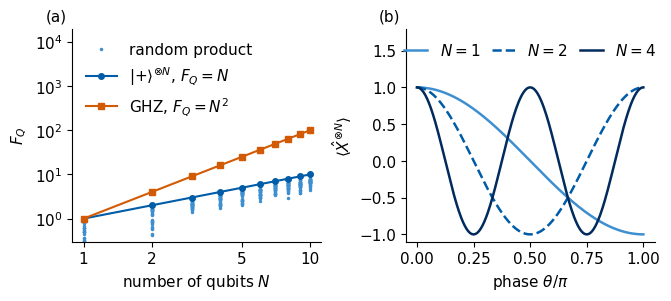

In [10]:
def jz_diag(N):
    b = (np.arange(2 ** N)[:, None] >> (N - 1 - np.arange(N))) & 1        # bits b_q of every basis index
    return 0.5 * (1 - 2 * b).sum(1)                                       # eigenvalue of J_z = sum_q (1 - 2 b_q) / 2

def qfi_pure(psi, jz):
    p = np.abs(psi) ** 2
    return 4 * (p @ jz ** 2 - (p @ jz) ** 2)

NQ = np.arange(1, 11)
F_prod, F_ghz, F_rand = [], [], []
for N in NQ:
    jz = jz_diag(N)
    prod = kron_all(*[plus] * N)
    ghz = np.zeros(2 ** N, dtype=complex); ghz[0] = ghz[-1] = 1 / np.sqrt(2)
    F_prod.append(qfi_pure(prod, jz)); F_ghz.append(qfi_pure(ghz, jz))
    rand_prod = [qfi_pure(kron_all(*haar_states(2, N)), jz) for _ in range(30)]
    assert max(rand_prod) <= N + 1e-9                                     # product states: F_Q <= N
    F_rand.append(rand_prod)
    # equation (18): fidelity with the state rotated by a small angle
    dth = 1e-4
    rot = np.exp(-1j * dth * jz) * ghz
    assert abs(8 * (1 - abs(np.vdot(ghz, rot))) / dth ** 2 - F_ghz[-1]) < 1e-3 * N ** 2
assert np.allclose(F_prod, NQ) and np.allclose(F_ghz, NQ ** 2)
NUMBERS["QFIGHZTen"] = f"{F_ghz[-1]:.0f}"

th = np.linspace(0, np.pi, 400)
def parity_ghz(N, th):
    vals = []
    for t in th:
        ghz = np.zeros(2 ** N, dtype=complex); ghz[0] = ghz[-1] = 1 / np.sqrt(2)
        psi = np.exp(-1j * t * jz_diag(N)) * ghz
        XN = kron_all(*[X] * N)
        vals.append(np.real(psi.conj() @ XN @ psi))
    return np.array(vals)
par = {N: parity_ghz(N, th) for N in (1, 2, 4)}
for N in par:
    assert np.allclose(par[N], np.cos(N * th))

# equation (20): Fisher information of the parity measurement, from finite differences of p_+-
for N in (1, 2, 4, 6):
    t0_, h_ = 0.31, 1e-5
    pplus = lambda t: 0.5 * (1 + parity_ghz(N, [t])[0])
    dp = (pplus(t0_ + h_) - pplus(t0_ - h_)) / (2 * h_)
    FC = dp ** 2 / pplus(t0_) + dp ** 2 / (1 - pplus(t0_))
    assert abs(FC - N ** 2) < 1e-4 * N ** 2 and FC <= N ** 2 + 1e-4 * N ** 2
print("parity measurement on GHZ: classical Fisher information N^2 = quantum Fisher information")

def panel_qfi_a(ax):
    for k, N in enumerate(NQ):
        ax.plot([N] * len(F_rand[k]), F_rand[k], ".", color=SKY, ms=3, label="random product" if k == 0 else None)
    ax.plot(NQ, F_prod, "o-", color=BLUE, ms=4, label=r"$|{+}\rangle^{\otimes N}$, $F_Q=N$")
    ax.plot(NQ, F_ghz, "s-", color=ORANGE, ms=4, label=r"GHZ, $F_Q=N^2$")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(r"$F_Q$"); ax.set_ylim(0.3, 2e4)
    ax.set_xticks([1, 2, 5, 10]); ax.set_xticklabels(["1", "2", "5", "10"]); ax.minorticks_off()
    ax.legend(frameon=False, loc="upper left")
def panel_qfi_b(ax):
    for N, c, ls in zip((1, 2, 4), (SKY, BLUE, NAVY), ("-", "--", "-")):
        ax.plot(th / np.pi, par[N], color=c, ls=ls, lw=1.8, label=f"$N={N}$")
    ax.set_xlabel(r"phase $\theta/\pi$"); ax.set_ylabel(r"$\langle\hat X^{\otimes N}\rangle$"); ax.set_ylim(-1.1, 1.8)
    ax.legend(frameon=False, loc="upper center", ncol=3, handlelength=1.5, columnspacing=0.8)
make_figures("qfi", [panel_qfi_a, panel_qfi_b])

Panel (a) shows the quantum Fisher information on logarithmic axes. Random product states (dots) stay below $F_Q=N$, the line of $|{+}\rangle^{\otimes N}$, and the GHZ state reaches $N^2$. By equation (19) the error of the phase at fixed $M$ falls as $1/\sqrt N$ for independent qubits and as $1/N$ for the GHZ state, the Heisenberg scaling. Panel (b) shows the origin of this gain, the parity fringe $\cos N\theta$, whose slope grows with $N$. The value $F_Q/N>1$ needs no knowledge of the state other than its Fisher information, which makes it a test of entanglement from measured data.

## 10. Exercises

The first five exercises belong to the core route, and the last two to Sections 7 to 9.

1. Show with equation (2) that a unitary which copies $|0\rangle$ and $|{+}\rangle$ cannot exist. Compute the fidelity $F(\vartheta,\varphi)$ of the CNOT copier for the state $\cos\frac\vartheta2|0\rangle+e^{i\varphi}\sin\frac\vartheta2|1\rangle$, show that $F=0$ for $|{-}\rangle$, and explain why the meridian $\varphi=0$ is the most favourable.
2. Find the optimal measurement and its success probability for telling $|{+}\rangle$ from the maximally mixed state $\hat I/2$. Compare with the trace distance of these states.
3. Compute the Holevo quantity of the four states $|0\rangle,|1\rangle,|{+}\rangle,|{-}\rangle$ used with equal probabilities, and explain why it equals one bit although four messages are sent.
4. Use the Pauli-string class to find the stabilisers of the state prepared by $\hat H_0$, $\hat H_1$ and $\widehat{\mathrm{CZ}}=(\hat I\otimes\hat H)\,\widehat{\mathrm{CNOT}}\,(\hat I\otimes\hat H)$, and check them with dense matrices.
5. Repeat Section 6 with $\hat P=\hat X_0\hat Z_1$ in place of $\hat Z_0$ and confirm that the variance does not change.
6. Compute the Choi state of phase damping and read off its Kraus operators. Compare them with $\hat K_0=\mathrm{diag}(1,\sqrt{1-\kappa})$ and $\hat K_1=\mathrm{diag}(0,\sqrt\kappa)$.
7. Compute the quantum Fisher information of the W state $(|001\rangle+|010\rangle+|100\rangle)/\sqrt3$ for the generator $\hat J_z$ and for $\hat J_x=\frac12\sum_j\hat X_j$. Explain why the first vanishes.

## 11. Summary

An unknown state cannot be copied, and two non-orthogonal states cannot be told apart with certainty from one copy. The best single-copy measurement projects on the positive part of $\hat\rho-\hat\sigma$ and succeeds with probability $\frac12(1+D)$. However many amplitudes the states of $N$ qubits have, a measurement on them yields at most $N$ bits about an encoded message. CNOT gates and single-qubit rotations build every unitary, but a generic unitary of $N$ qubits needs a number of gates that grows as $4^N$. Clifford circuits map Pauli strings to Pauli strings, which a classical computer follows with a bit update even for a thousand entangled qubits, and the $\hat T$ gate makes the gate set universal. Expectation values of random states concentrate at zero with the variance $1/(2^N+1)$, and random Clifford circuits reproduce these second moments. The Choi state stores a channel as a two-qubit state and gives its Kraus operators, the partial transpose detects the entanglement of mixed states, and the quantum Fisher information turns entanglement into a phase precision beyond that of independent qubits. The next notebook turns to physical qubits, an atom driven by laser light.